# Stage 1 — Data pipeline

Crack segmentation and measurement project. Explanations: see the study guide.

In [13]:
# Cell 1 — Imports and settings
from pathlib import Path
import random
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

DATA_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

TRAIN_SOURCES = ["CRACK500", "Rissbilder", "Noncrack", "Volker", "GAPS384", "Misc"]
UNSEEN_SOURCES = ["DeepCrack", "CFD", "Ceramic"]   # never used for training or tuning
EXCLUDED_SOURCES = ["CrackTree200"]                # one-pixel centre-line labels
SPLIT_FRACTIONS = {"train": 0.8, "val": 0.1, "test_seen": 0.1}

In [14]:
# Cell 2 — Rebuild the index from Stage 0
folders = {p.name: p for p in DATA_ROOT.rglob("*")
           if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}

SOURCE_RULES = [
    ("CRACK500", "CRACK500"), ("Rissbilder", "Rissbilder"), ("noncrack", "Noncrack"),
    ("DeepCrack", "DeepCrack"), ("Volker", "Volker"), ("GAPS384", "GAPS384"),
    ("cracktree200", "CrackTree200"), ("CFD", "CFD"), ("Ceramic", "Ceramic"),
]

def source_of(name):
    for prefix, source in SOURCE_RULES:
        if name.startswith(prefix):
            return source
    return "Misc"

def parent_of(name, source):
    stem = name.rsplit(".", 1)[0]
    parts = stem.split("_")
    if source in ("CRACK500", "GAPS384"):
        return "_".join(parts[1:3])
    if source == "Rissbilder":
        return parts[3]
    if source == "Volker":
        return parts[1]
    if source == "Noncrack":
        return "_".join(parts[:5])
    if source == "DeepCrack":
        return stem.split("_", 1)[1].split("-")[0]
    if source == "Misc":
        return "_".join(parts[:2])
    return stem

rows = []
for folder in ("Images", "Images-2"):
    for img_path in sorted(folders[folder].glob("*.png")):
        source = source_of(img_path.name)
        rows.append({
            "name": img_path.name,
            "source": source,
            "parent": f"{source}/{parent_of(img_path.name, source)}",
            "image": str(img_path),
            "mask": str(folders["Masks"] / img_path.name),
        })
df = pd.DataFrame(rows)
print(len(df), "images")

9159 images


In [15]:
# Cell 3 — Assign splits by parent photo
def assign_splits(frame, fractions, seed):
    rng = np.random.default_rng(seed)
    split_of_parent = {}
    for source in TRAIN_SOURCES:
        parents = np.array(sorted(frame.loc[frame["source"] == source, "parent"].unique()))
        rng.shuffle(parents)
        n = len(parents)
        n_train = int(round(fractions["train"] * n))
        n_val = int(round(fractions["val"] * n))
        for k, parent in enumerate(parents):
            if k < n_train:
                split_of_parent[parent] = "train"
            elif k < n_train + n_val:
                split_of_parent[parent] = "val"
            else:
                split_of_parent[parent] = "test_seen"
    split = frame["parent"].map(split_of_parent)
    split[frame["source"].isin(UNSEEN_SOURCES)] = "test_unseen"
    split[frame["source"].isin(EXCLUDED_SOURCES)] = "excluded"
    return split

df["split"] = assign_splits(df, SPLIT_FRACTIONS, SEED)
order = ["train", "val", "test_seen", "test_unseen", "excluded"]
print(pd.crosstab(df["source"], df["split"], margins=True).reindex(columns=order + ["All"], fill_value=0))

split         train  val  test_seen  test_unseen  excluded   All
source                                                          
CFD               0    0          0          118         0   118
CRACK500       2486  292        348            0         0  3126
Ceramic           0    0          0          100         0   100
CrackTree200      0    0          0            0       175   175
DeepCrack         0    0          0          443         0   443
GAPS384         305   38         40            0         0   383
Misc            181   28         31            0         0   240
Noncrack       1023  232        156            0         0  1411
Rissbilder     2211  206        319            0         0  2736
Volker          344   44         39            0         0   427
All            6550  840        933          661       175  9159


In [16]:
# Cell 4 — Check that no photo appears in two splits
parents_by_split = df.groupby("split")["parent"].apply(set)
for i, a in enumerate(order):
    for b in order[i + 1:]:
        shared = parents_by_split.get(a, set()) & parents_by_split.get(b, set())
        assert not shared, f"{len(shared)} photos shared between {a} and {b}"
print("OK: every photo belongs to exactly one split")

OK: every photo belongs to exactly one split


In [17]:
# Cell 5 — Augmentations
CROP = 384   # training crop; divisible by 32, as the U-Net needs
PAD = 416    # evaluation size: 400 padded up to the next multiple of 32

train_tf = A.Compose([
    A.RandomCrop(height=CROP, width=CROP),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.Normalize(),            # ImageNet mean and std, matching the pretrained encoder
    ToTensorV2(),
])

eval_tf = A.Compose([
    A.PadIfNeeded(min_height=PAD, min_width=PAD, border_mode=cv2.BORDER_REFLECT_101),
    A.Normalize(),
    ToTensorV2(),
])

In [18]:
# Cell 6 — Dataset class
def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

class CrackDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = np.array(Image.open(row["image"]).convert("RGB"))   # H x W x 3, uint8
        mask = load_mask(row["mask"]).astype(np.uint8)              # H x W, 0 or 1
        out = self.transform(image=image, mask=mask)                # same flips/crops for both
        return out["image"], out["mask"].unsqueeze(0).float()       # 3 x H x W, 1 x H x W

datasets = {
    "train": CrackDataset(df[df["split"] == "train"], train_tf),
    "val": CrackDataset(df[df["split"] == "val"], eval_tf),
    "test_seen": CrackDataset(df[df["split"] == "test_seen"], eval_tf),
    "test_unseen": CrackDataset(df[df["split"] == "test_unseen"], eval_tf),
}
for name, ds in datasets.items():
    print(f"{name:12s} {len(ds):5d} images")

train         6550 images
val            840 images
test_seen      933 images
test_unseen    661 images


In [19]:
# Cell 7 — Inspect one sample
image, mask = datasets["train"][0]
print("image:", tuple(image.shape), image.dtype, f"min {image.min():.2f} max {image.max():.2f}")
print("mask: ", tuple(mask.shape), mask.dtype, "values", torch.unique(mask).tolist())

image, mask = datasets["val"][0]
print("val image:", tuple(image.shape), " val mask:", tuple(mask.shape))

image: (3, 384, 384) torch.float32 min -1.52 max 1.58
mask:  (1, 384, 384) torch.float32 values [0.0, 1.0]
val image: (3, 416, 416)  val mask: (1, 416, 416)


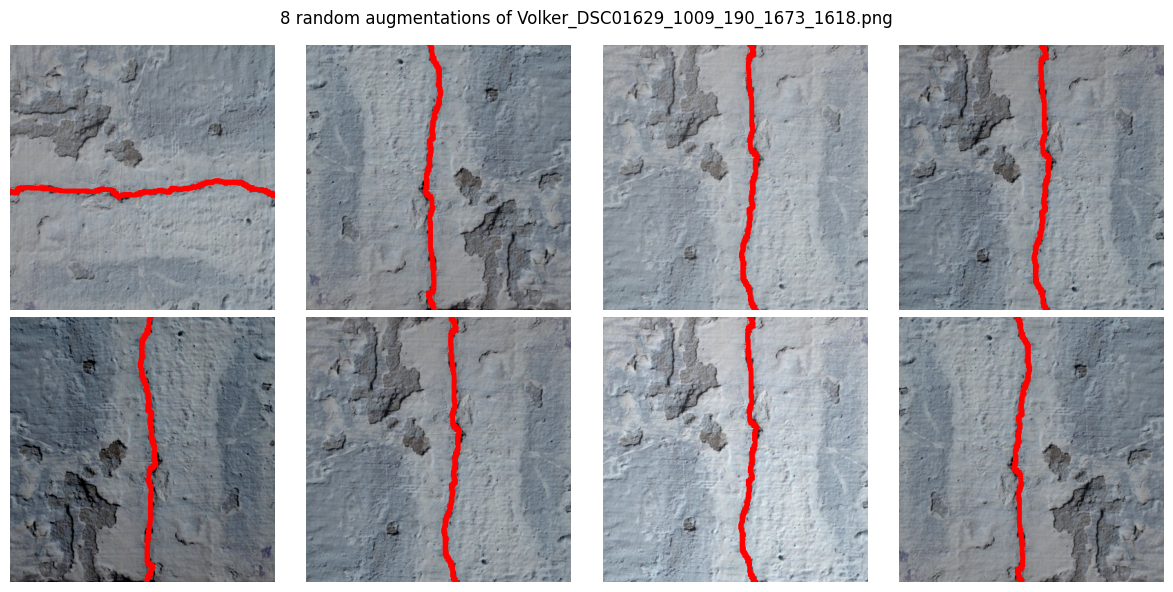

In [20]:
# Cell 8 — See what augmentation does
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def to_display(image_tensor):
    img = image_tensor.permute(1, 2, 0).numpy() * STD + MEAN   # undo Normalize
    return np.clip(img, 0, 1)

train_df = datasets["train"].frame
idx = int(train_df.index[train_df["name"].str.startswith("Volker")][0])
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.ravel():
    image, mask = datasets["train"][idx]          # a new random augmentation every call
    shown = to_display(image)
    shown[mask[0].numpy() > 0] = [1, 0, 0]
    ax.imshow(shown)
    ax.axis("off")
fig.suptitle(f"8 random augmentations of {train_df.loc[idx, 'name']}")
plt.tight_layout()
plt.show()

In [21]:
# Cell 9 — DataLoader: batches and loading speed
train_loader = DataLoader(datasets["train"], batch_size=16, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
start = time.time()
for b, (images, masks) in enumerate(train_loader):
    if b == 0:
        print("batch images:", tuple(images.shape), " batch masks:", tuple(masks.shape))
        print(f"crack pixels in first batch: {100 * masks.mean():.2f}%")
    if b == 19:
        break
per_batch = (time.time() - start) / 20
print(f"{per_batch:.2f} s per batch -> about {per_batch * len(train_loader) / 60:.1f} min "
      f"to read one epoch of {len(train_loader)} batches")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


batch images: (16, 3, 384, 384)  batch masks: (16, 1, 384, 384)
crack pixels in first batch: 2.60%
0.19 s per batch -> about 1.3 min to read one epoch of 409 batches


In [22]:
# Cell 10 — Save the splits
df[["name", "source", "parent", "split"]].to_csv(OUT_DIR / "splits.csv", index=False)
print("Saved", OUT_DIR / "splits.csv")

Saved /kaggle/working/splits.csv
